# Real Estate Valuation — House Price Prediction
**Machine Learning Mini Project**

**Problem:** Predict the *house price per unit area* of a property from its age, location and nearby facilities.

- **Target:** `price_per_unit_area` (in 10,000 New Taiwan Dollars per Ping; 1 Ping = 3.3 m²)
- **Task type:** Regression (the output is a number, not a category)
- **Who could use it:** a buyer or seller who wants a rough idea of a fair price
- **Limitation:** academic prototype; 414 sales from one district of Taiwan (2012–2013). Not for real financial decisions.

**Dataset:** Real Estate Valuation, UCI Machine Learning Repository — https://archive.ics.uci.edu/dataset/477/real+estate+valuation+data+set

## 1. Import libraries

In [1]:
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

## 2. Load the dataset

In [2]:
df = pd.read_csv("../data/dataset.csv")
df.head()

,No,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
0,1,2012.916667,32.0,84.87882,10,24.98298,121.54024,37.9
1,2,2012.916667,19.5,306.59470,9,24.98034,121.53951,42.2
2,3,2013.583333,13.3,561.98450,5,24.98746,121.54391,47.3
3,4,2013.500000,13.3,561.98450,5,24.98746,121.54391,54.8
4,5,2012.833333,5.0,390.56840,5,24.97937,121.54245,43.1


The original column names are long, so we rename them to short names. `No` is only a serial number (an identifier), so we remove it.

In [3]:
FEATURES = ["transaction_date", "house_age", "distance_to_mrt",
            "convenience_stores", "latitude", "longitude"]
TARGET = "price_per_unit_area"

df.columns = ["No"] + FEATURES + [TARGET]
df = df.drop(columns=["No"])
df.head()

,transaction_date,house_age,distance_to_mrt,convenience_stores,latitude,longitude,price_per_unit_area
0,2012.916667,32.0,84.87882,10,24.98298,121.54024,37.9
1,2012.916667,19.5,306.59470,9,24.98034,121.53951,42.2
2,2013.583333,13.3,561.98450,5,24.98746,121.54391,47.3
3,2013.500000,13.3,561.98450,5,24.98746,121.54391,54.8
4,2012.833333,5.0,390.56840,5,24.97937,121.54245,43.1


## 3. Data understanding

In [4]:
print("Rows, Columns:", df.shape)
df.info()

Rows, Columns: (414, 7)
<class 'pandas.DataFrame'>
RangeIndex: 414 entries, 0 to 413
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   transaction_date     414 non-null    float64
 1   house_age            414 non-null    float64
 2   distance_to_mrt      414 non-null    float64
 3   convenience_stores   414 non-null    int64  
 4   latitude             414 non-null    float64
 5   longitude            414 non-null    float64
 6   price_per_unit_area  414 non-null    float64
dtypes: float64(6), int64(1)
memory usage: 22.8 KB


All 7 columns are **numerical** — there are no categorical (text) columns, so no encoding is needed.

In [5]:
print("Missing values per column:")
print(df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())

Missing values per column:
transaction_date       0
house_age              0
distance_to_mrt        0
convenience_stores     0
latitude               0
longitude              0
price_per_unit_area    0
dtype: int64

Duplicate rows: 0


In [6]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
transaction_date,414.0,2013.15,0.28,2012.67,2012.92,2013.17,2013.42,2013.58
house_age,414.0,17.71,11.39,0.00,9.02,16.10,28.15,43.80
distance_to_mrt,414.0,1083.89,1262.11,23.38,289.32,492.23,1454.28,6488.02
convenience_stores,414.0,4.09,2.95,0.00,1.00,4.00,6.00,10.00
latitude,414.0,24.97,0.01,24.93,24.96,24.97,24.98,25.01
longitude,414.0,121.53,0.02,121.47,121.53,121.54,121.54,121.57
price_per_unit_area,414.0,37.98,13.61,7.60,27.70,38.45,46.60,117.50


**Observations**
- 414 records, 6 input features, 1 target.
- No missing values and no duplicate rows.
- `distance_to_mrt` ranges from about 23 m to about 6,488 m — a much bigger scale than the other features. This is why we use **scaling**.
- The maximum price (117.5) is far above the 75% value (about 46.6), so there is at least one unusually expensive house.

## 4. Exploratory Data Analysis (EDA)

### 4.1 Distribution of the target

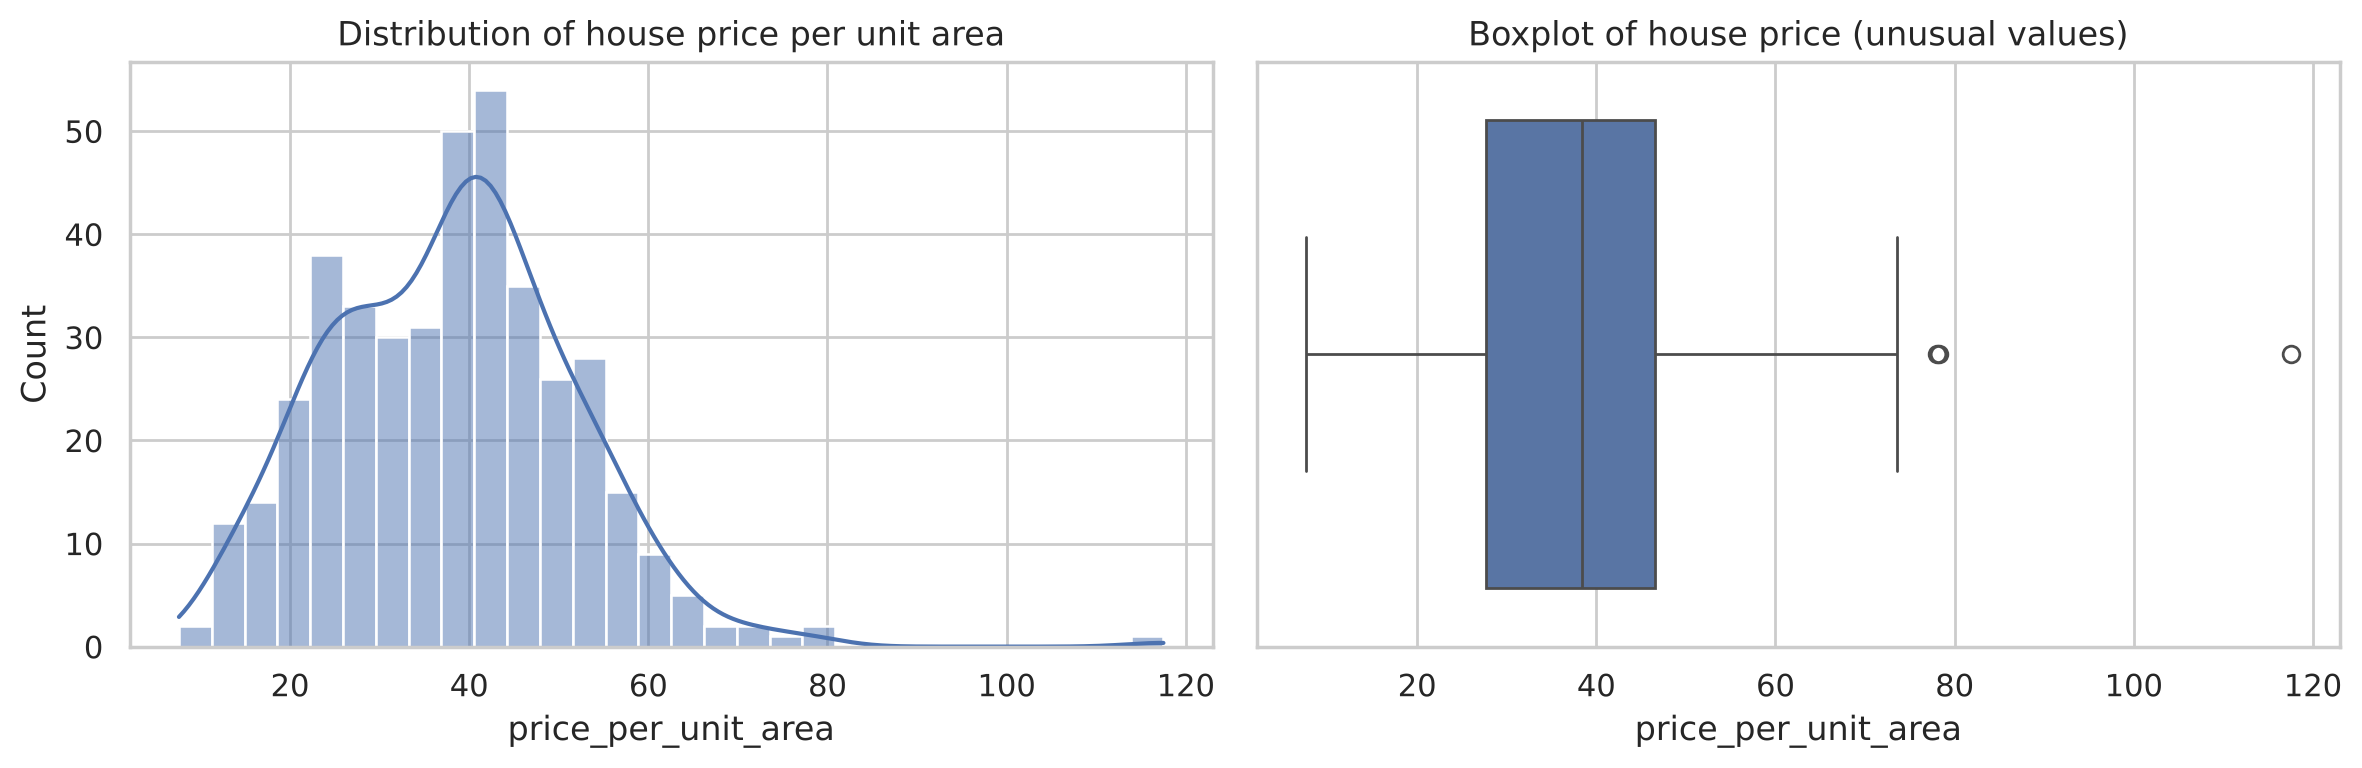

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df[TARGET], bins=30, kde=True, ax=ax[0])
ax[0].set_title("Distribution of house price per unit area")
sns.boxplot(x=df[TARGET], ax=ax[1])
ax[1].set_title("Boxplot of house price (unusual values)")
plt.tight_layout(); plt.show()

In [8]:
df[df[TARGET] > 80]

,transaction_date,house_age,distance_to_mrt,convenience_stores,latitude,longitude,price_per_unit_area
270,2013.333333,10.8,252.5822,1,24.9746,121.53046,117.5


Most prices lie between 20 and 60. Only one house is priced above 80 — a single sale at 117.5, far above the next highest (78.3). We have no evidence that it is a data-entry error, so we keep it, but it will make the error (RMSE) larger in whichever part of the data it falls.

### 4.2 Correlation between variables

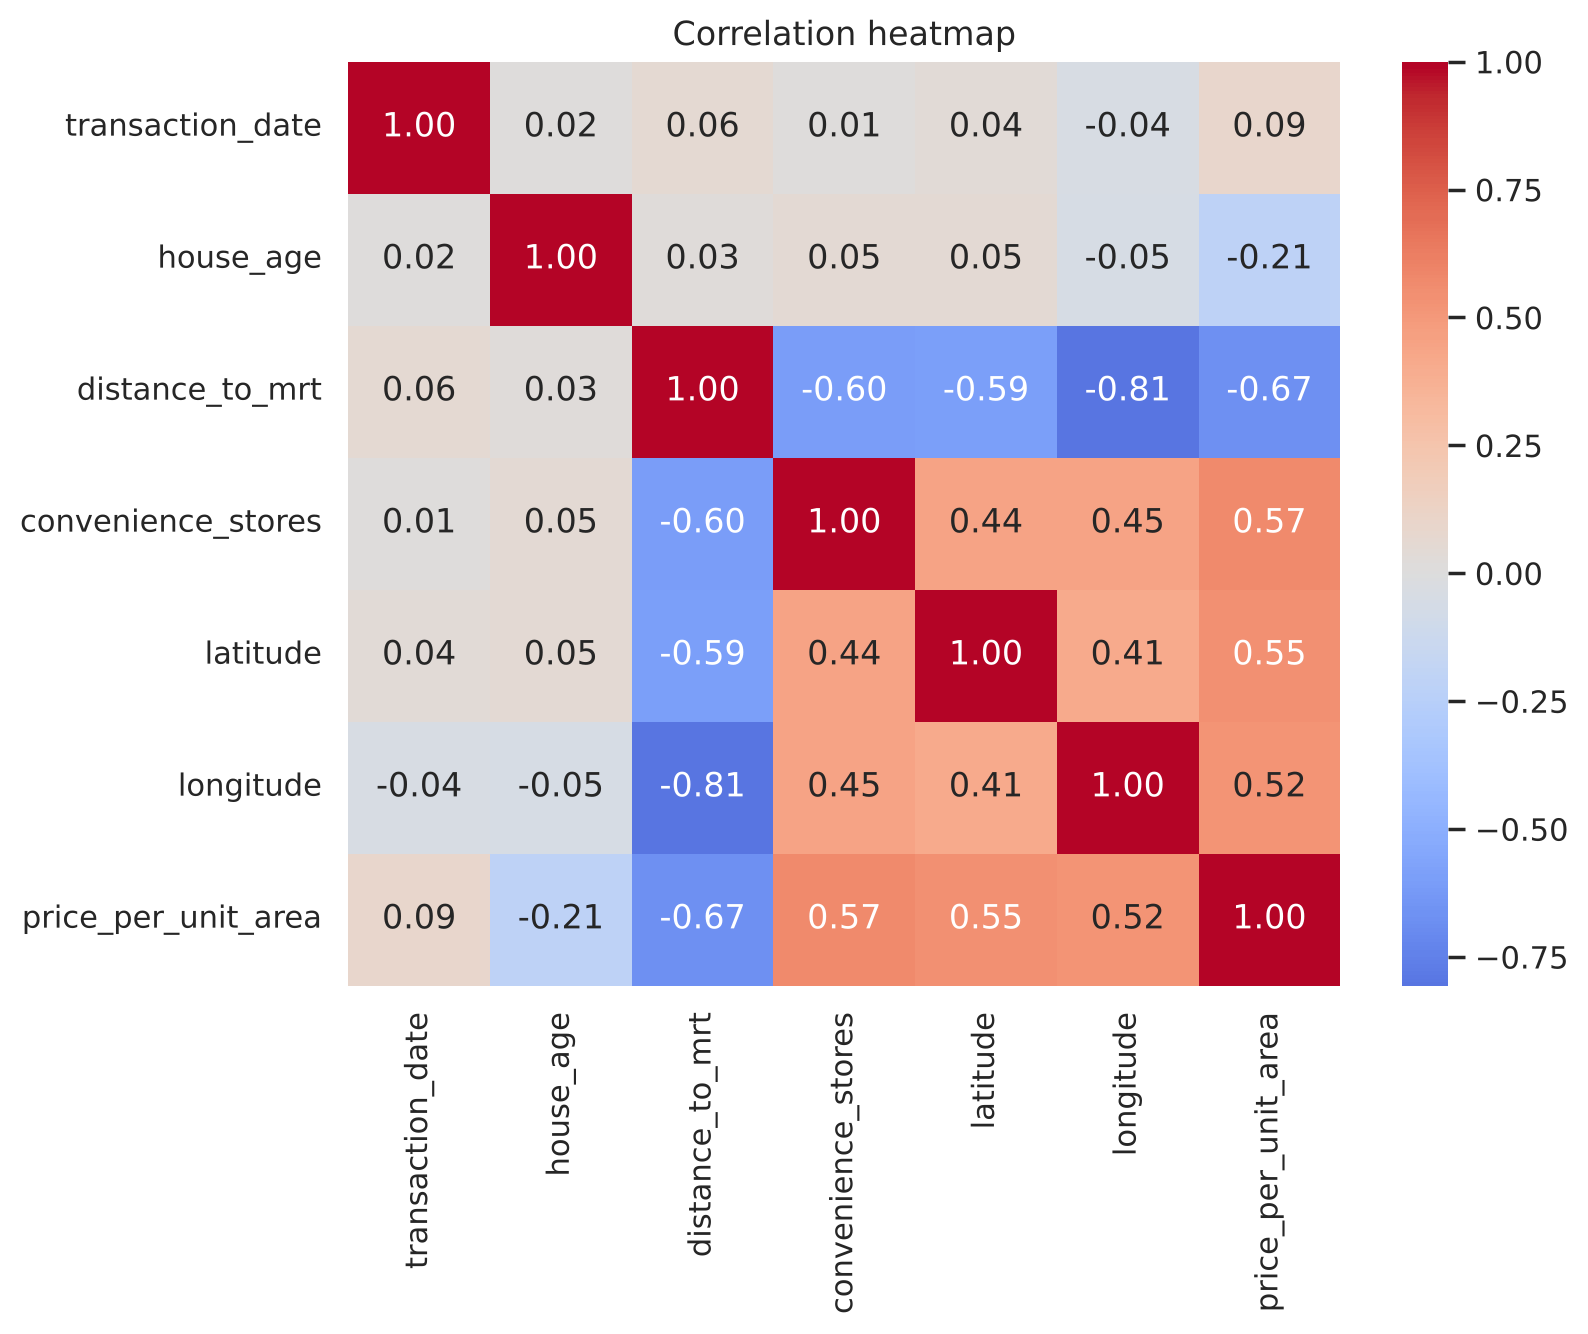

In [9]:
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap")
plt.show()

- `distance_to_mrt` has the strongest relation with price, and it is **negative**: farther from the metro → cheaper.
- `convenience_stores`, `latitude` and `longitude` have a **positive** relation with price.
- `house_age` and `transaction_date` have only a weak straight-line relation.

### 4.3 Each feature against price

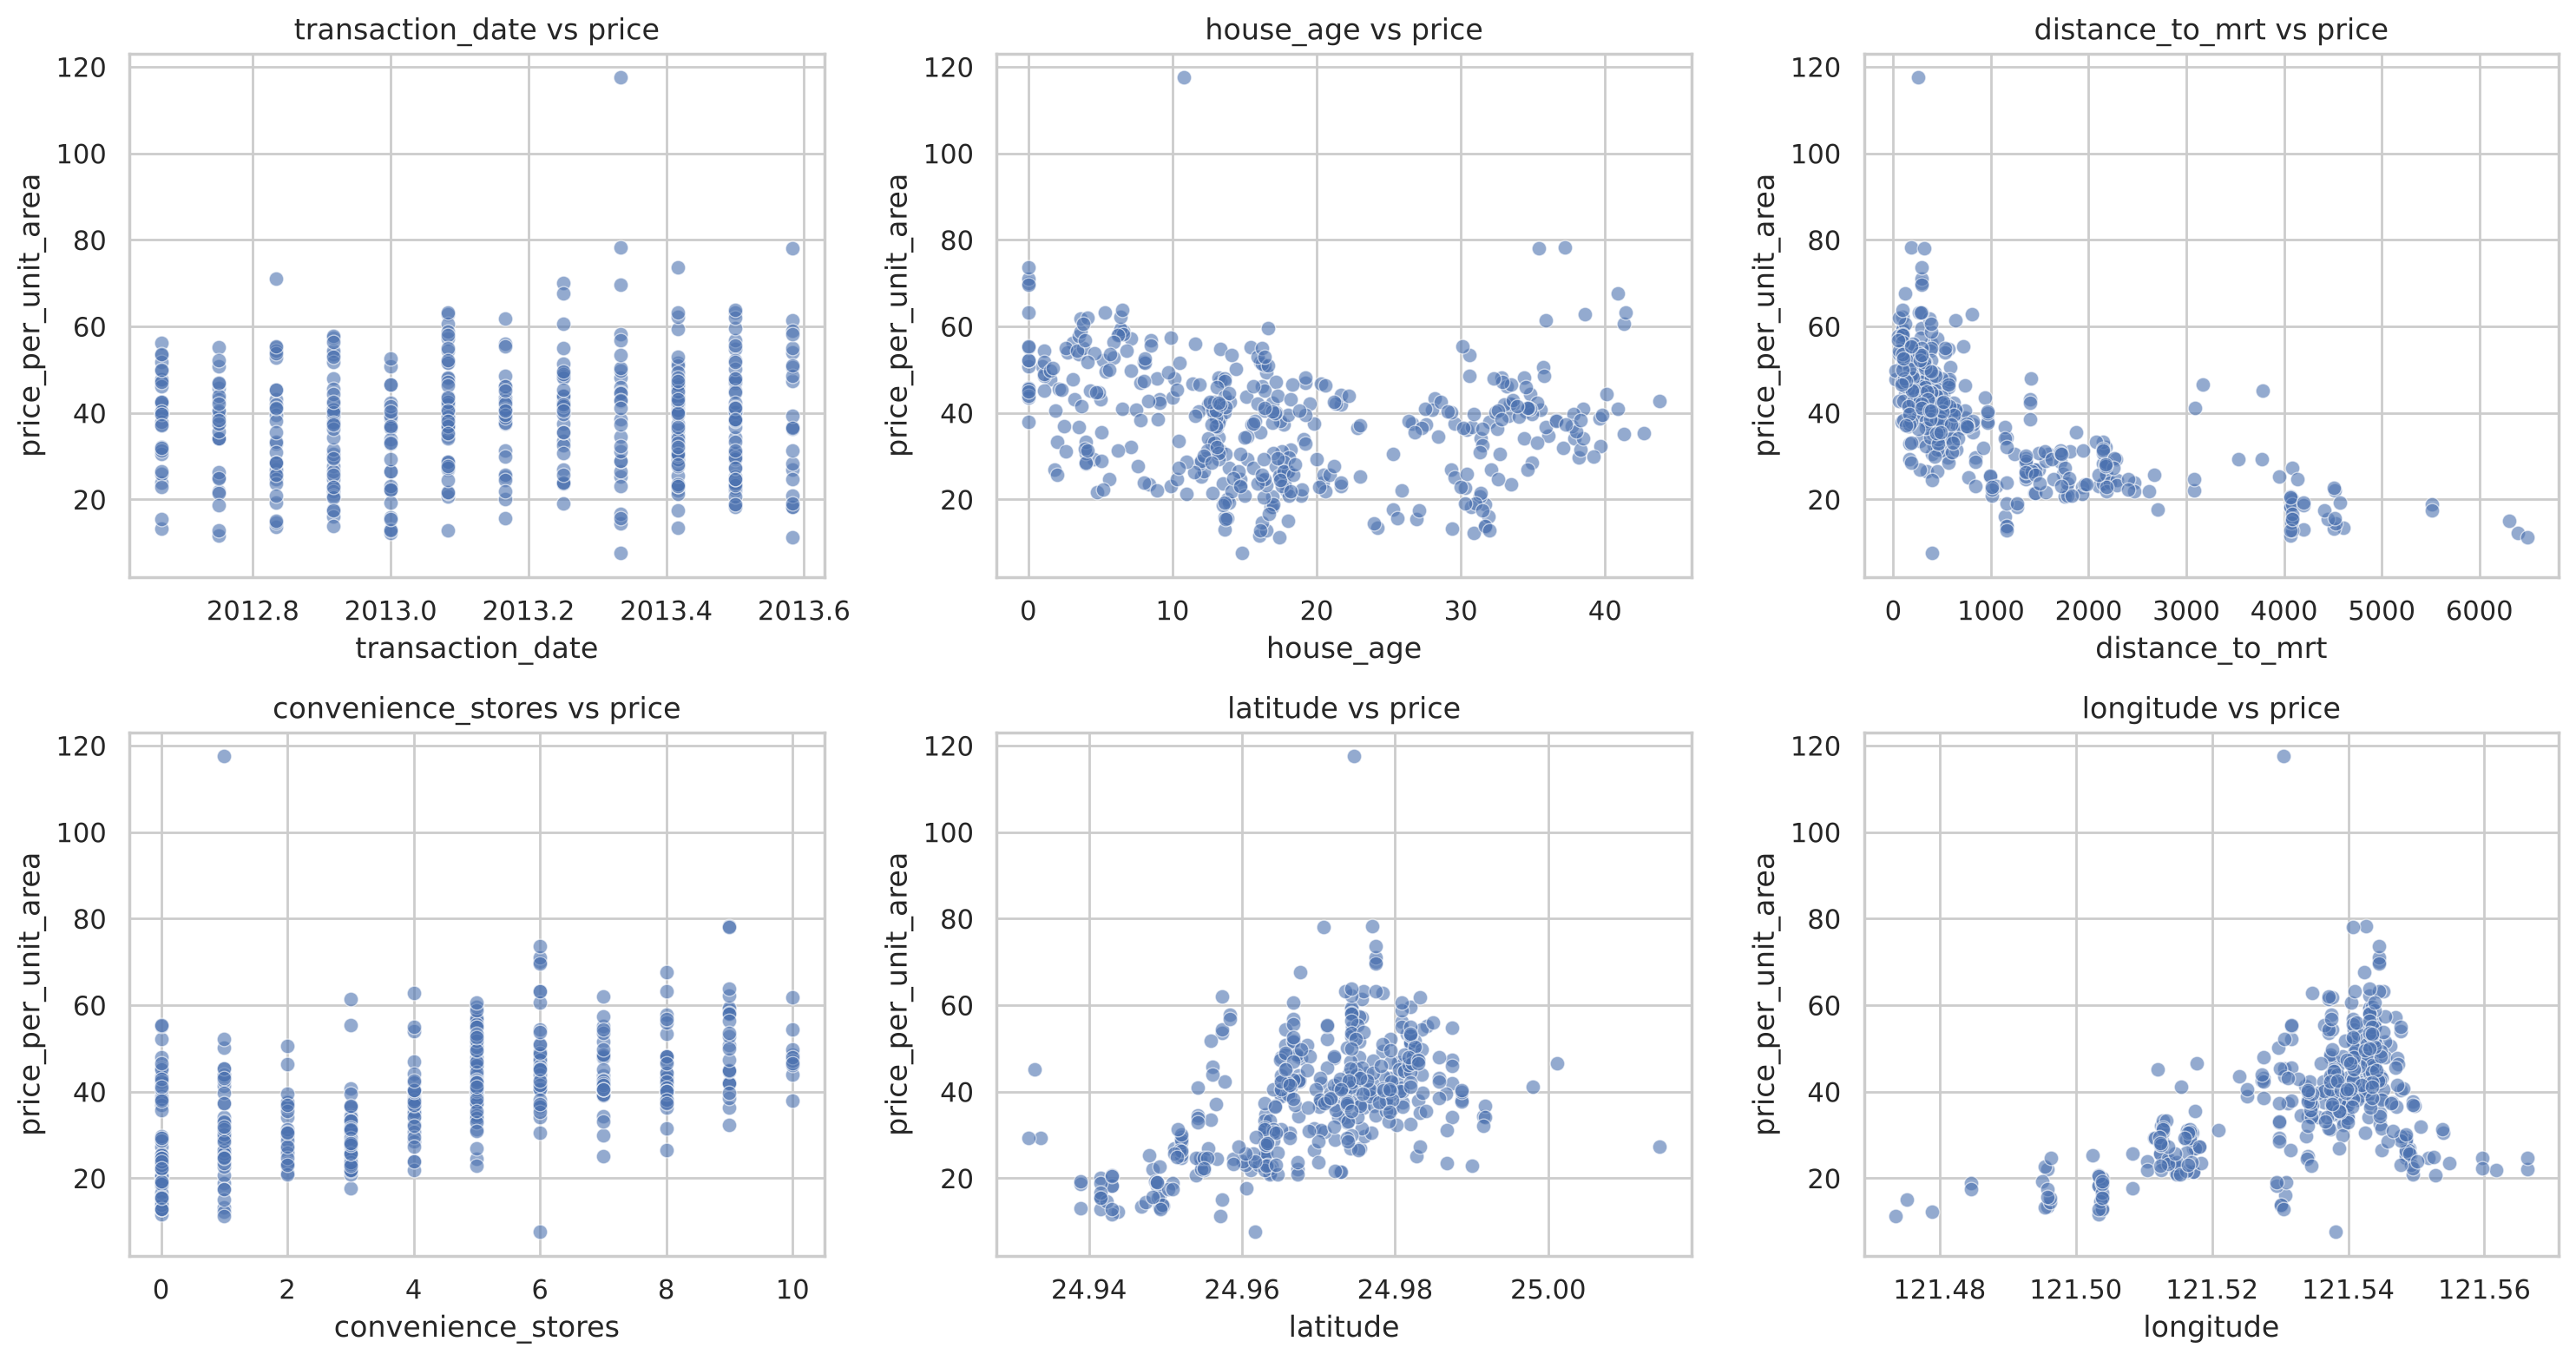

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), FEATURES):
    sns.scatterplot(x=df[col], y=df[TARGET], alpha=0.6, ax=ax)
    ax.set_title(f"{col} vs price")
plt.tight_layout(); plt.show()

The relation between distance and price is a **curve**, not a straight line: price falls quickly in the first 1,000 m and then flattens. Models that can learn curves (KNN, trees, Random Forest) may therefore do better than Linear Regression. This guides our model choice.

## 5. Preprocessing and train-test split

- Missing values: none, so nothing to fill.
- Identifier `No`: already removed.
- Encoding: not needed (all numeric).
- Scaling: done with `StandardScaler` **inside a Pipeline**, so it is learned from training data only and never from test data.

We keep 20% of the data aside as the **test set**. It is used only once, at the very end.

In [11]:
X = df[FEATURES]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE)

print("Training rows:", X_train.shape[0])
print("Testing rows :", X_test.shape[0])

Training rows: 331
Testing rows : 83


## 6. Model building and comparison (with 5-fold cross-validation)

We compare four regression algorithms. Each one is placed in a Pipeline: **scaler → model**.

In 5-fold cross-validation the training data is cut into 5 parts. The model is trained 5 times; each time 4 parts are used for training and 1 part for checking. The average score is more reliable than a single split.

In [12]:
models = {
    "Linear Regression": LinearRegression(),
    "KNN Regressor": KNeighborsRegressor(),
    "Decision Tree": DecisionTreeRegressor(random_state=RANDOM_STATE),
    "Random Forest": RandomForestRegressor(random_state=RANDOM_STATE),
}

rows = []
for name, model in models.items():
    pipe = Pipeline([("scaler", StandardScaler()), ("model", model)])
    r2   =  cross_val_score(pipe, X_train, y_train, cv=5, scoring="r2")
    rmse = -cross_val_score(pipe, X_train, y_train, cv=5, scoring="neg_root_mean_squared_error")
    mae  = -cross_val_score(pipe, X_train, y_train, cv=5, scoring="neg_mean_absolute_error")
    rows.append([name, mae.mean(), rmse.mean(), r2.mean(), r2.std()])

results = pd.DataFrame(rows, columns=["Model", "CV MAE", "CV RMSE", "CV R2", "R2 std"])
results = results.sort_values("CV RMSE").reset_index(drop=True)
results.round(3)

,Model,CV MAE,CV RMSE,CV R2,R2 std
0,Random Forest,5.166,8.141,0.630,0.126
1,KNN Regressor,6.032,8.803,0.576,0.081
2,Linear Regression,6.445,9.179,0.540,0.087
3,Decision Tree,6.628,10.794,0.296,0.454


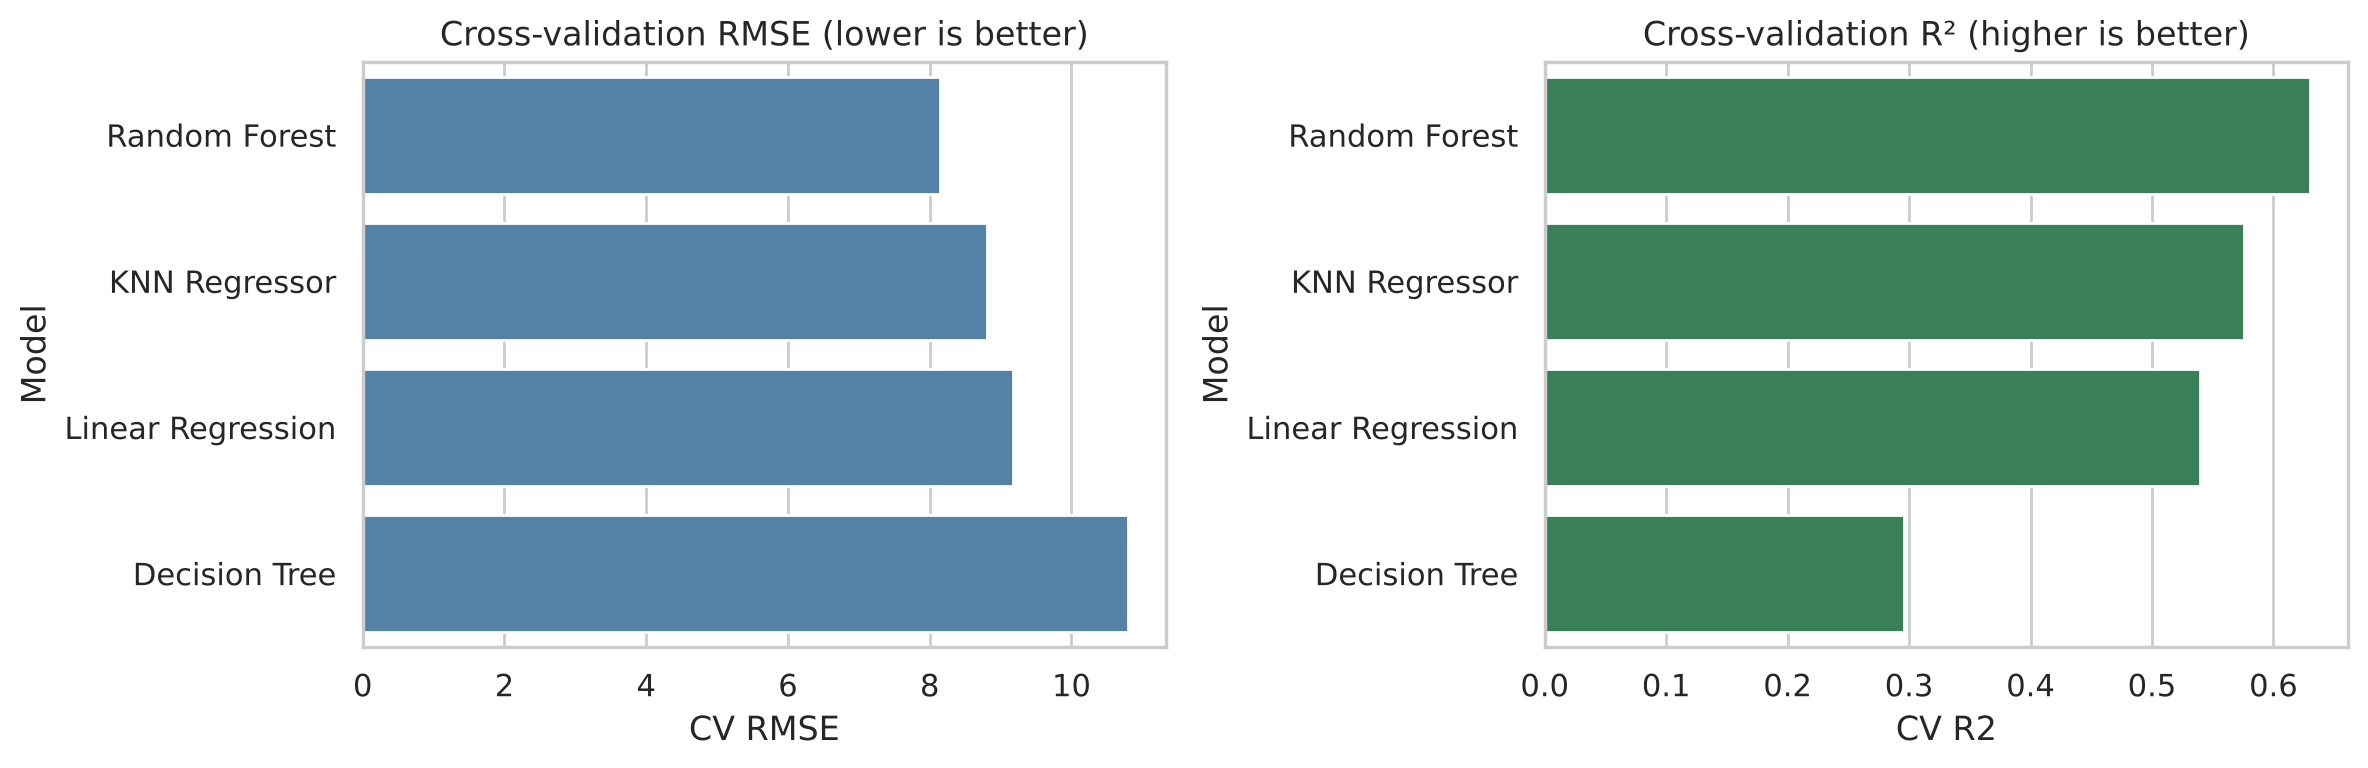

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(data=results, x="CV RMSE", y="Model", ax=ax[0], color="steelblue")
ax[0].set_title("Cross-validation RMSE (lower is better)")
sns.barplot(data=results, x="CV R2", y="Model", ax=ax[1], color="seagreen")
ax[1].set_title("Cross-validation R² (higher is better)")
plt.tight_layout(); plt.show()

**Metrics**
- **MAE** – average size of the mistake (in price units). Easy to explain.
- **RMSE** – like MAE but punishes big mistakes more.
- **R²** – how much of the price variation the model explains (1.0 = perfect, 0 = no better than guessing the average).

**Which model and why?**
- **Random Forest** has the lowest MAE and RMSE and the highest R².
- **Decision Tree** is the weakest and its R² changes a lot from fold to fold (large std) — a single tree overfits this small dataset.
- **Linear Regression** is the simplest and most explainable, but it cannot follow the curved distance–price relation seen in the EDA.
- Random Forest averages many trees, so it handles the curve and is more stable than one tree. The cost is that it is harder to explain than Linear Regression — acceptable here because the goal is an accurate estimate.

So we select **Random Forest** for tuning.

## 7. Hyperparameter tuning with GridSearchCV

Hyperparameters are settings we choose *before* training. GridSearchCV tries every combination below with 5-fold cross-validation (3 × 3 × 3 = 27 combinations × 5 folds = 135 trainings) and keeps the best.

| Hyperparameter | Meaning | Values tested |
|---|---|---|
| `n_estimators` | number of trees | 100, 200, 300 |
| `max_depth` | how deep each tree can grow | None (no limit), 5, 10 |
| `min_samples_leaf` | minimum houses in a final leaf | 1, 2, 4 |

In [14]:
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", RandomForestRegressor(random_state=RANDOM_STATE)),
])

param_grid = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [None, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
}

grid = GridSearchCV(pipeline, param_grid, cv=5,
                    scoring="neg_root_mean_squared_error", n_jobs=-1)
grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best CV RMSE   :", round(-grid.best_score_, 3))

Best parameters: {'model__max_depth': None, 'model__min_samples_leaf': 4, 'model__n_estimators': 300}
Best CV RMSE   : 7.837


In [15]:
cv_table = pd.DataFrame(grid.cv_results_)[
    ["param_model__n_estimators", "param_model__max_depth",
     "param_model__min_samples_leaf", "mean_test_score"]].copy()
cv_table["CV RMSE"] = -cv_table["mean_test_score"]
cv_table.drop(columns="mean_test_score").sort_values("CV RMSE").head(5).round(3)

,param_model__n_estimators,param_model__max_depth,param_model__min_samples_leaf,CV RMSE
8,300,None,4,7.837
26,300,10,4,7.837
7,200,None,4,7.873
25,200,10,4,7.873
6,100,None,4,7.874


Tuning lowered the cross-validation RMSE compared with the default Random Forest. `min_samples_leaf = 4` makes each tree a little simpler, which reduces overfitting.

## 8. Best pipeline and final test

Only now do we touch the test set — once. This tells us how the selected model performs on houses it has never seen.

In [16]:
best_pipeline = grid.best_estimator_
y_pred = best_pipeline.predict(X_test)

mae  = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2   = r2_score(y_test, y_pred)

print("MAE :", round(mae, 3))
print("RMSE:", round(rmse, 3))
print("R2  :", round(r2, 3))

MAE : 3.671
RMSE: 5.457
R2  : 0.822


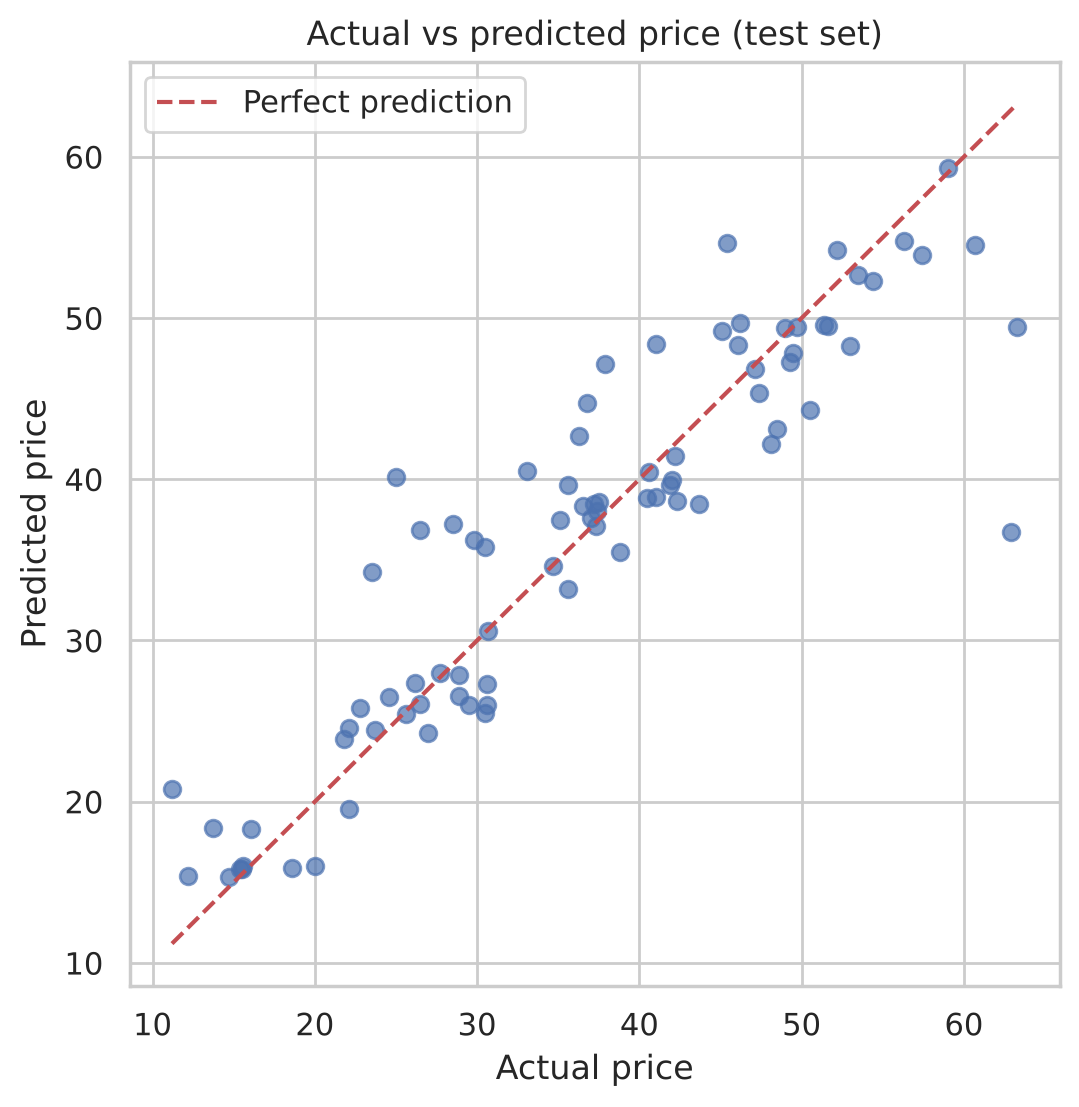

In [17]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.7)
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(lims, lims, "r--", label="Perfect prediction")
plt.xlabel("Actual price"); plt.ylabel("Predicted price")
plt.title("Actual vs predicted price (test set)")
plt.legend(); plt.show()

Points close to the red line are good predictions. The test scores are better than the cross-validation scores. A likely reason is that the 117.5 house fell in the training part (the highest price in the test set is 63.3), which made one training fold harder; with only 83 test rows the test score also depends on which rows were picked. So the honest expectation for new data lies somewhere between the CV result and the test result.

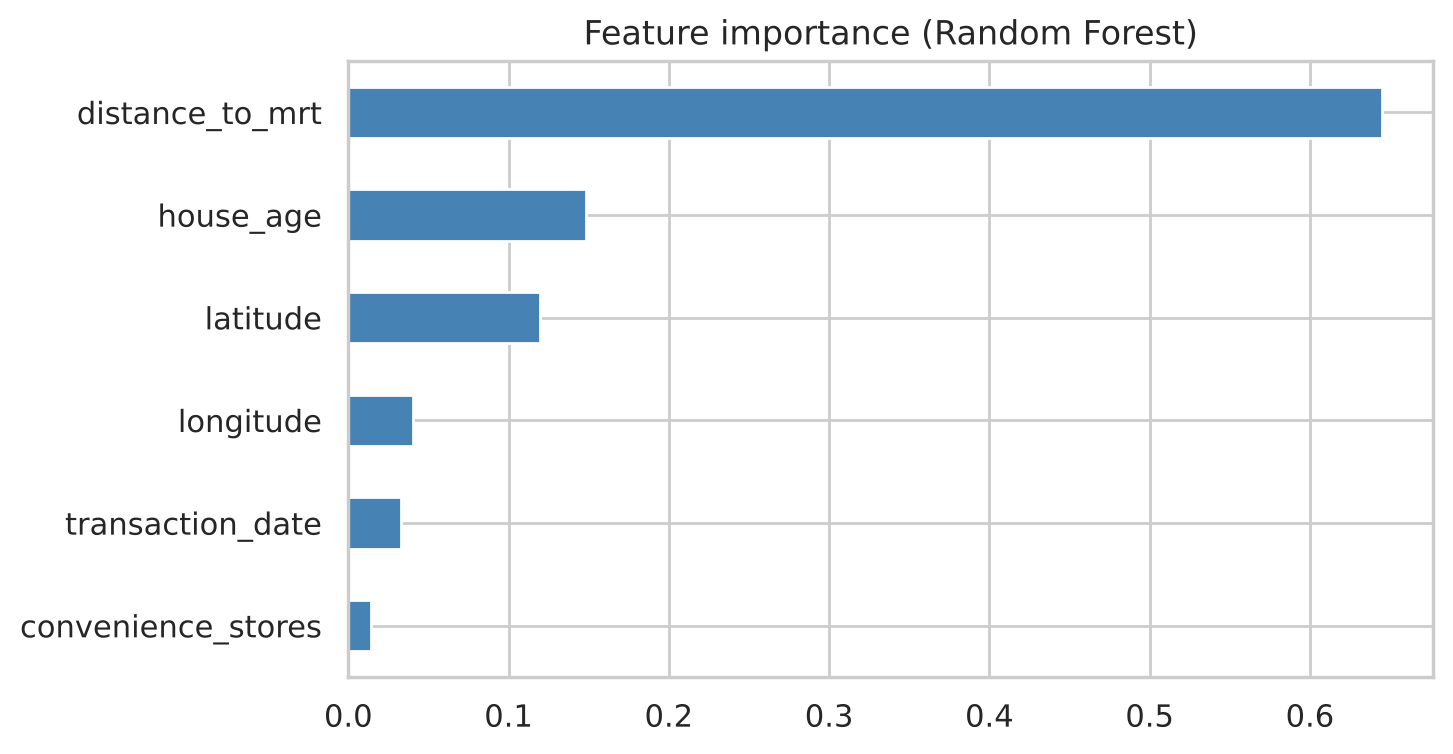

In [18]:
importance = pd.Series(best_pipeline.named_steps["model"].feature_importances_,
                       index=FEATURES).sort_values()
importance.plot(kind="barh", figsize=(7, 4), color="steelblue")
plt.title("Feature importance (Random Forest)")
plt.show()

`distance_to_mrt` is by far the most important feature, which agrees with the correlation heatmap.

## 9. Save the final pipeline with pickle

We save the **whole pipeline** (scaler + model). The Streamlit app loads this file and predicts directly — no retraining.

In [19]:
with open("../model.pkl", "wb") as f:
    pickle.dump(best_pipeline, f)

# Check: load it back and predict for one example house
with open("../model.pkl", "rb") as f:
    loaded = pickle.load(f)

example = pd.DataFrame([[2013.5, 10.0, 500.0, 4, 24.97, 121.53]], columns=FEATURES)
print("Predicted price:", round(float(loaded.predict(example)[0]), 2), "x 10,000 NT$ per Ping")

Predicted price: 46.94 x 10,000 NT$ per Ping


## 10. Conclusion
- Compared 4 regression models using 5-fold cross-validation; Random Forest was best.
- Tuned it with GridSearchCV and evaluated once on the held-out test set.
- Saved the complete pipeline to `model.pkl` for the Streamlit app.

**Limitations:** small dataset (414 rows), one district of Taiwan, data from 2012–2013, a few extreme prices. The model is an educational prototype and must not be used for real property decisions.